# Comparison and analysis (Parts c, d, e, f)

Reads the saved results of `01_configA_cnn.ipynb` and `02_resnet_B_Bp_C.ipynb` and turns them into the
tables and figures for the report. **No training and no GPU**: only the CSVs in `outputs/` and the images
in `datasets/val` and `datasets/test` are used.

| Section | Report part |
|---|---|
| 0. Setup | — |
| 1. Load and check the results | — |
| 2. Main results table | d, f |
| 3. Comparison chain B → B′ → C-noaug → C, and A vs C | f |
| 4. Training curves and the augmentation effect | b, f |
| 5. Learning-rate sweep | c |
| 6. Error analysis of Config C | e |
| 7. Config A vs Config C, image by image | e, f |
| 8. Summary for the report | — |

**How to run:** select the `ie4483-venv` kernel, then Kernel → Restart, Run All. Every figure is also saved
to `outputs/`, so the report can use them after the cell outputs are cleared.

## 0. Setup

**Needed:**
- Imports: pandas, numpy, matplotlib, PIL, scikit-learn metrics
- Paths and constants from `common.py`: `OUTPUT_DIR`, `DATA_DIR`, `CLASS_TO_IDX`, `SEED`
- One fixed colour per config, used in every figure
- Small helpers: save a figure to `outputs/`, compute a 95% confidence interval for an accuracy

**Output files** (in `outputs/`): none (setup only)

In [21]:
# Output file: none (setup only)
from math import sqrt

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.stats import binomtest
from sklearn.metrics import classification_report, confusion_matrix

from common import CLASS_TO_IDX, DATA_DIR, OUTPUT_DIR, SEED, SUBSET_SIZE

IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}   # 0 -> "cat", 1 -> "dog"

# One fixed colour per config, the same in every figure (colour-blind-safe palette).
CONFIGS = {
    "A":       {"label": "A: custom CNN (scratch)",       "color": "#2a78d6"},
    "B":       {"label": "B: frozen ResNet-18 + SVM",     "color": "#eb6834"},
    "Bp":      {"label": "B′: frozen ResNet-18 + linear", "color": "#1baf7a"},
    "C-noaug": {"label": "C-noaug: fine-tuned without aug",   "color": "#eda100"},
    "C":       {"label": "C: fine-tuned + aug (final)",   "color": "#6250d6"},
}
SWEEP = {"sweep-lr1e-3": 1e-3, "sweep-lr1e-4": 1e-4, "sweep-lr1e-5": 1e-5}
SWEEP_COLORS = {"sweep-lr1e-3": "#2a78d6", "sweep-lr1e-4": "#eb6834", "sweep-lr1e-5": "#1baf7a"}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def save(fig, name):
    """Save a figure to outputs/ so the report can use it after outputs are cleared."""
    path = OUTPUT_DIR / name
    fig.savefig(path)
    print("saved", path.relative_to(OUTPUT_DIR.parent).as_posix())


def wilson_ci(acc, n, z=1.96):
    """95% confidence interval for an accuracy measured on n images (Wilson score interval)."""
    centre = (acc + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * sqrt(acc * (1 - acc) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


print("data:", DATA_DIR, "| outputs:", OUTPUT_DIR)

data: C:\Users\qihen\Documents\NTU\Y4S1\IE4483-Project\datasets | outputs: C:\Users\qihen\Documents\NTU\Y4S1\IE4483-Project\outputs


## 1. Load and check the results

**Inputs:**
- `outputs/results_<config>_seed42.csv` for A, B, Bp, C-noaug, C (one row per epoch; B has one row)
- `outputs/results_sweep-lr{1e-3,1e-4,1e-5}_seed42.csv` (3 epochs each, on the subset)
- `outputs/preds_A_seed42.csv`, `outputs/preds_C_seed42.csv` (per-image val predictions)

**Checks:** every run is complete (15 epochs, sweep 3 epochs), all evaluated on `val`, all on the same GPU,
5,000 val images. Print the `git_commit` of each run (note any `-dirty` tag for the report).

**Output files** (in `outputs/`): none (loads and checks the results)

In [22]:
# Output file: none (display only)
def load_results(config):
    return pd.read_csv(OUTPUT_DIR / f"results_{config}_seed{SEED}.csv")


results = {c: load_results(c) for c in CONFIGS}   # one DataFrame per config, one row per epoch
sweep = {c: load_results(c) for c in SWEEP}
preds = {c: pd.read_csv(OUTPUT_DIR / f"preds_{c}_seed{SEED}.csv") for c in ["A", "C"]}

N_VAL = len(preds["C"])
all_runs = pd.concat([*results.values(), *sweep.values()])

# One line per run: how many epochs, which split, GPU and code version produced it.
check = all_runs.groupby("config", sort=False).agg(
    epochs=("epoch", "max"), split=("eval_split", "first"),
    gpu=("gpu", "first"), git_commit=("git_commit", "first"))
print(check.to_string())

# Every trained config must have had the same budget, and the sweep runs the same length.
trained = ["A", "Bp", "C-noaug", "C"]
assert len({len(results[c]) for c in trained}) == 1, "trained configs ran different numbers of epochs"
assert len(results["B"]) == 1, "B (SVM) should have a single row"
assert len({len(s) for s in sweep.values()}) == 1, "sweep runs have different lengths"

# Comparable runs: all evaluated on val, all on the same GPU.
assert (all_runs.eval_split == "val").all()
assert all_runs.gpu.nunique() == 1, "runs come from different GPUs: not comparable"

# Predictions cover the whole val set, the same images for A and C.
n_val_images = sum(1 for _ in (DATA_DIR / "val").glob("*/*.jpg"))
assert len(preds["A"]) == N_VAL == n_val_images, "predictions do not cover the full val set"
assert set(preds["A"].path) == set(preds["C"].path)

dirty = sorted(all_runs.loc[all_runs.git_commit.str.endswith("-dirty"), "config"].unique())
print(f"\nAll checks passed: {len(results)} configs + {len(sweep)} sweep runs on {all_runs.gpu.iloc[0]}, "
      f"trained configs {len(results['C'])} epochs each; {N_VAL} val images (1 image = {100 / N_VAL:.2f} percentage points)")
if dirty:
    print("Note for the report: run with uncommitted changes (-dirty):", ", ".join(dirty))

              epochs split          gpu     git_commit
config                                                
A                 15   val  NVIDIA L40S        fea3316
B                  1   val  NVIDIA L40S  fea3316-dirty
Bp                15   val  NVIDIA L40S  fea3316-dirty
C-noaug           15   val  NVIDIA L40S  fea3316-dirty
C                 15   val  NVIDIA L40S  fea3316-dirty
sweep-lr1e-3       3   val  NVIDIA L40S  fea3316-dirty
sweep-lr1e-4       3   val  NVIDIA L40S  fea3316-dirty
sweep-lr1e-5       3   val  NVIDIA L40S  fea3316-dirty

All checks passed: 5 configs + 3 sweep runs on NVIDIA L40S, trained configs 15 epochs each; 5000 val images (1 image = 0.02 percentage points)
Note for the report: run with uncommitted changes (-dirty): B, Bp, C, C-noaug, sweep-lr1e-3, sweep-lr1e-4, sweep-lr1e-5


## 2. Main results table (Parts d, f)

**Needed:** one row per config with
- best validation accuracy and the epoch it occurred (the checkpoint that was kept)
- 95% confidence interval and number of misclassified val images
- training accuracy and validation loss at that epoch
- starting learning rate and total training time

**Output files** (in `outputs/`): `comparison_table.csv`, `fig_misclassified.png`

In [23]:
# Output file: outputs/comparison_table.csv
rows = []
for c, df in results.items():
    best = df.loc[df.eval_acc.idxmax()]          # the epoch whose checkpoint was kept
    lo, hi = wilson_ci(best.eval_acc, N_VAL)
    rows.append({
        "config": c,
        "model": CONFIGS[c]["label"],
        "best_val_acc": best.eval_acc,
        "ci95_low": round(lo, 4),
        "ci95_high": round(hi, 4),
        "val_misclassified": round((1 - best.eval_acc) * N_VAL),
        "best_epoch": int(best.epoch),
        "epochs_run": int(df.epoch.max()),
        "train_acc_at_best": best.train_acc,
        "val_loss_at_best": best.eval_loss,
        "lr_start": df.lr.iloc[0],
        "train_seconds": round(df.seconds.sum(), 1),
    })
table = pd.DataFrame(rows).set_index("config")
table.to_csv(OUTPUT_DIR / "comparison_table.csv")
print("saved outputs/comparison_table.csv")
table.drop(columns="model")

saved outputs/comparison_table.csv


,best_val_acc,ci95_low,ci95_high,val_misclassified,best_epoch,epochs_run,train_acc_at_best,val_loss_at_best,lr_start,train_seconds
config,,,,,,,,,,
A,0.9112,0.9030,0.9188,444,15,15,0.91760,0.22742,0.0010,402.8
B,0.9898,0.9866,0.9922,51,1,1,NaN,NaN,NaN,10.1
Bp,0.9884,0.9850,0.9910,58,8,15,0.99075,0.03234,0.0010,16.8
C-noaug,0.9906,0.9875,0.9929,47,11,15,0.99995,0.04690,0.0001,311.3
C,0.9910,0.9880,0.9933,45,11,15,0.99890,0.03704,0.0001,374.4


saved outputs/fig_misclassified.png


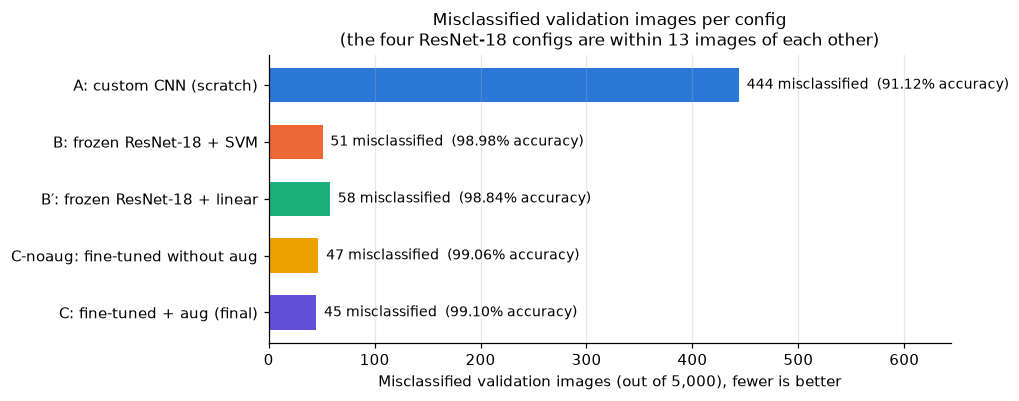

In [24]:
# Output file: outputs/fig_misclassified.png
# Number of misclassified val images per config: fewer is better.
order = list(CONFIGS)
wrong_per_config = table.loc[order, "val_misclassified"]

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.barh([CONFIGS[c]["label"] for c in order], wrong_per_config,
               color=[CONFIGS[c]["color"] for c in order], height=0.6)
for bar, c in zip(bars, order):
    r = table.loc[c]
    ax.annotate(f"{int(r.val_misclassified)} misclassified  ({100 * r.best_val_acc:.2f}% accuracy)",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, wrong_per_config.max() * 1.45)   # room for the labels
ax.set_xlabel(f"Misclassified validation images (out of {N_VAL:,}), fewer is better")
ax.grid(axis="y", visible=False)

resnet = ["B", "Bp", "C-noaug", "C"]
spread = int(table.loc[resnet, "val_misclassified"].max() - table.loc[resnet, "val_misclassified"].min())
ax.set_title(f"Misclassified validation images per config\n(the four ResNet-18 configs are within {spread} images "
             f"of each other)", fontsize=11)
save(fig, "fig_misclassified.png")
plt.show()

## 3. Comparison chain (Part f)

Each step changes **exactly one thing**, so any difference can be attributed to that change:

```
B ──────────► B′ ──────────────► C-noaug ──────────► C
   SVM → FC       frozen → fine-tuned     no aug → aug
 (classifier)       (fine-tuning)         (augmentation)
```

plus **A vs C** (scratch CNN vs pretrained ResNet-18 at the same budget).

The ResNet configs differ by only a few images, so before interpreting a difference we ask **whether it is
bigger than chance**. Three checks, all from the results CSVs:

- **Noise floor:** how much a config's own val accuracy moves over its last 5 epochs, with nothing changed.
  A step whose difference is no bigger than this cannot be told apart from epoch-to-epoch wobble.
- **Mean of the last 5 epochs:** a fairer score than the best epoch, which picks the luckiest of 15 values.
  (B has a single score, so it gets no such advantage.)
- **95% interval of the difference:** combines the uncertainty of both accuracies (5,000 val images each).
  If it contains 0, we cannot say the change helped or hurt.

For augmentation (C-noaug → C) we also compare the **train–val gap** (overfitting), as the plan requires.

**Output files** (in `outputs/`): `comparison_chain.csv`; also adds 3 columns to `comparison_table.csv`

In [25]:
# Output file: outputs/comparison_table.csv (adds 3 columns and saves it again)
LAST_K = 5   # epochs used for the "mean of last epochs" and the noise floor
mean_col = f"mean_last{LAST_K}_val_acc"

# Add three columns to the section 2 table (one row per config), then save it again.
for c, df in results.items():
    last = df.eval_acc.tail(LAST_K)
    single = len(df) == 1                       # B: one score, no epochs
    table.loc[c, mean_col] = table.loc[c, "best_val_acc"] if single else round(last.mean(), 5)
    table.loc[c, "noise_floor_images"] = np.nan if single else round((last.max() - last.min()) * N_VAL)
    table.loc[c, "train_val_gap_pp"] = round(100 * (table.loc[c, "train_acc_at_best"] - table.loc[c, "best_val_acc"]), 3)

table.to_csv(OUTPUT_DIR / "comparison_table.csv")
print("updated outputs/comparison_table.csv with", mean_col, "noise_floor_images, train_val_gap_pp")
print(f"noise floor = max − min val accuracy over the last {LAST_K} epochs, in images "
      f"(1 image = {100 / N_VAL:.2f} pp); B has a single score")
table[["best_val_acc", mean_col, "noise_floor_images", "train_val_gap_pp", "val_loss_at_best"]].round(4)

updated outputs/comparison_table.csv with mean_last5_val_acc noise_floor_images, train_val_gap_pp
noise floor = max − min val accuracy over the last 5 epochs, in images (1 image = 0.02 pp); B has a single score


,best_val_acc,mean_last5_val_acc,noise_floor_images,train_val_gap_pp,val_loss_at_best
config,,,,,
A,0.9112,0.9034,81.0,0.640,0.2274
B,0.9898,0.9898,NaN,NaN,NaN
Bp,0.9884,0.9878,5.0,0.235,0.0323
C-noaug,0.9906,0.9893,13.0,0.935,0.0469
C,0.9910,0.9905,4.0,0.790,0.0370


In [26]:
# Output file: outputs/comparison_chain.csv
Z95 = 1.96   # 95% two-sided

steps = [
    ("B", "Bp", "classifier: SVM → linear layer"),
    ("Bp", "C-noaug", "fine-tuning: frozen → layer4 trained"),
    ("C-noaug", "C", "augmentation: off → on"),
    ("A", "C", "scratch CNN → pretrained ResNet-18"),
]
chain = []
for a, b, what in steps:
    pa, pb = table.loc[a, "best_val_acc"], table.loc[b, "best_val_acc"]
    diff = pb - pa
    half = Z95 * sqrt(pa * (1 - pa) / N_VAL + pb * (1 - pb) / N_VAL)   # interval of a difference of two accuracies
    lo, hi = diff - half, diff + half
    verdict = "real improvement" if lo > 0 else "real decline" if hi < 0 else "within noise"
    mean_diff = table.loc[b, mean_col] - table.loc[a, mean_col]
    chain.append({
        "step": f"{a} → {b}",
        "what changes": what,
        "best acc before → after": f"{100 * pa:.2f}% → {100 * pb:.2f}%",
        "diff_pp": round(100 * diff, 2),
        "diff_ci95_pp": f"{100 * lo:+.2f} to {100 * hi:+.2f}",
        "diff_images": round(diff * N_VAL),
        f"diff_mean_last{LAST_K}_pp": round(100 * mean_diff, 2),
        "same direction": bool(np.sign(mean_diff) == np.sign(diff)),
        "noise_floor_images": table.loc[[a, b], "noise_floor_images"].max(),
        "verdict": verdict,
    })
chain = pd.DataFrame(chain)
chain.to_csv(OUTPUT_DIR / "comparison_chain.csv", index=False)
print("saved outputs/comparison_chain.csv")
print("noise_floor_images = the larger noise floor of the two configs in the step")
chain

saved outputs/comparison_chain.csv
noise_floor_images = the larger noise floor of the two configs in the step


,step,what changes,best acc before → after,diff_pp,diff_ci95_pp,diff_images,diff_mean_last5_pp,same direction,noise_floor_images,verdict
0,B → Bp,classifier: SVM → linear layer,98.98% → 98.84%,-0.14,-0.55 to +0.27,-7,-0.20,True,5.0,within noise
1,Bp → C-noaug,fine-tuning: frozen → layer4 trained,98.84% → 99.06%,0.22,-0.18 to +0.62,11,0.16,True,13.0,within noise
2,C-noaug → C,augmentation: off → on,99.06% → 99.10%,0.04,-0.33 to +0.41,2,0.12,True,13.0,within noise
3,A → C,scratch CNN → pretrained ResNet-18,91.12% → 99.10%,7.98,+7.15 to +8.81,399,8.71,True,81.0,real improvement


In [27]:
# Output file: none (display only)
# Augmentation step in detail: train–val gap at the best epoch and over the last epochs.
aug = pd.DataFrame({c: {
    "best val acc": results[c].eval_acc.max(),
    "train acc at best epoch": results[c].loc[results[c].eval_acc.idxmax(), "train_acc"],
    "train–val gap at best epoch (pp)": table.loc[c, "train_val_gap_pp"],
    f"mean train–val gap, last {LAST_K} epochs (pp)":
        100 * (results[c].train_acc - results[c].eval_acc).tail(LAST_K).mean(),
    "lowest val loss": results[c].eval_loss.min(),
    "epoch of lowest val loss": int(results[c].loc[results[c].eval_loss.idxmin(), "epoch"]),
    "final val loss": results[c].eval_loss.iloc[-1],
    f"noise floor, last {LAST_K} epochs (images)": table.loc[c, "noise_floor_images"],
} for c in ["C-noaug", "C"]})
aug.round(5)   # 5 decimals: C-noaug's train acc is 0.99995, not 1

,C-noaug,C
best val acc,0.99060,0.99100
train acc at best epoch,0.99995,0.99890
train–val gap at best epoch (pp),0.93500,0.79000
"mean train–val gap, last 5 epochs (pp)",1.05400,0.86400
lowest val loss,0.03338,0.02978
epoch of lowest val loss,1.00000,3.00000
final val loss,0.04461,0.03612
"noise floor, last 5 epochs (images)",13.00000,4.00000


### What the chain shows

Read together with the tables above (the numbers are computed there):

- **B → B′ (classifier type):** the SVM and the linear layer see the *same* 512 frozen features, and
  their difference is within noise. Once the pretrained features separate cats from dogs this well, the choice
  of classifier on top barely matters: the features do the work. B′ is even favoured by the comparison
  (best of 15 epochs vs B's single score) and still does not beat B.
- **B′ → C-noaug (fine-tuning):** letting layer4 adapt gives a small gain, but it is within the
  interval and about the size of the noise floor, so with one seed and 5,000 images it cannot be confirmed.
  ImageNet already contains many cat and dog breeds, so frozen features leave little room to improve.
- **C-noaug → C (augmentation):** val accuracy is the same within noise. The effect of augmentation
  shows instead in **overfitting and stability**: C-noaug fits the training set almost perfectly (largest
  train–val gap) and its val accuracy wobbles more between epochs; C has a smaller gap and a lower noise floor.
  *Caveat:* C's training accuracy is measured on augmented images, which are harder, so part of its smaller gap
  comes from that; the val-loss curves in section 4 give a cleaner view.
- **A vs C (pretraining + architecture):** by far the largest effect, a real improvement on every
  measure (best epoch, mean of last epochs, interval far from 0). *Limitation:* architecture and pretraining
  both differ, so this is their combined effect, not pretraining alone.

**Overall:** the choice that matters is **starting from a pretrained network**. After that, classifier type,
fine-tuning and augmentation each change only a handful of images, no more than a single model's own
epoch-to-epoch variation. C is kept as the final model because it is tied for the best accuracy and is the most
stable and least overfit of the top configs, not because it is proven more accurate.

*Limits of this comparison (state in the report):* one seed per config, so the intervals cover the choice of
validation images but not training randomness; per-image predictions exist only for A and C, so the chain steps
use unpaired intervals (A vs C is tested image by image in section 7).

## 4. Training curves and the augmentation effect (Parts b, f)

How each model learned over the 15 epochs, from the per-epoch rows of the results CSVs.

- **Training curves** for A, B′, C-noaug and C (B has no curve: the SVM is fitted once), training and
  validation, with grey dotted lines where StepLR halved the learning rate (read from the `lr` column)
  → `outputs/fig_curves.png`
- **Augmentation, C-noaug vs C:** does the validation loss get worse while training continues (overfitting)?
  → `outputs/fig_aug_val_loss.png`

**Caveat:** for A and C, training loss/accuracy are measured on *augmented* images (and with dropout on for
A), which are harder than the plain validation images. So their training curves can sit *above* the
validation curves, and a train–val gap is not a clean comparison between C and C-noaug. The validation loss
is measured the same way for every config, so it is the fair measure of overfitting.

**Output files** (in `outputs/`): `fig_curves.png`, `fig_aug_val_loss.png`

learning rate halved before epochs: [4, 7, 10, 13]
saved outputs/fig_curves.png


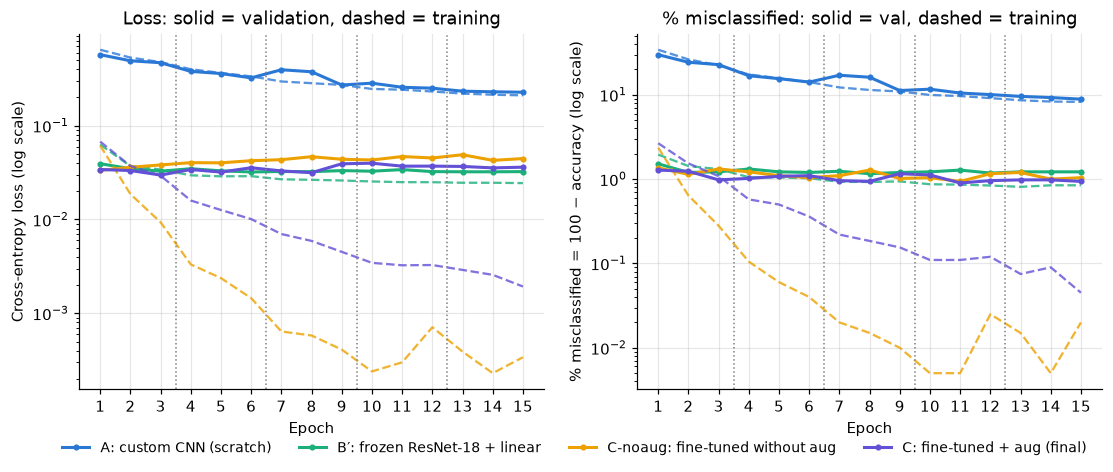

In [28]:
# Output file: outputs/fig_curves.png
curve_configs = ["A", "Bp", "C-noaug", "C"]

# Epochs where the learning rate changed (StepLR), read from the lr column: draw a line just before them.
lr_col = results["C"].set_index("epoch").lr
lr_drops = [e - 0.5 for e in lr_col.index[1:] if lr_col[e] != lr_col[e - 1]]
print("learning rate halved before epochs:", [int(x + 0.5) for x in lr_drops])

# Log scales: A (~9% wrong, loss ~0.2-0.6) is ten times worse than the ResNet configs (~1%, ~0.03);
# on a normal scale the ResNet curves would be flat lines on top of each other.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for c in curve_configs:
    df, col = results[c], CONFIGS[c]["color"]
    axes[0].plot(df.epoch, df.eval_loss, "-o", ms=3, lw=2, color=col, label=CONFIGS[c]["label"])
    axes[0].plot(df.epoch, df.train_loss, "--", lw=1.5, color=col, alpha=0.8)
    axes[1].plot(df.epoch, 100 * (1 - df.eval_acc), "-o", ms=3, lw=2, color=col)
    axes[1].plot(df.epoch, 100 * (1 - df.train_acc), "--", lw=1.5, color=col, alpha=0.8)
for ax in axes:
    for x in lr_drops:
        ax.axvline(x, color="grey", ls=":", lw=1)
    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_xticks(results["C"].epoch)
axes[0].set_ylabel("Cross-entropy loss (log scale)")
axes[0].set_title("Loss: solid = validation, dashed = training")
axes[1].set_ylabel("% misclassified = 100 − accuracy (log scale)")
axes[1].set_title("% misclassified: solid = val, dashed = training")
fig.legend(loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.06), frameon=False)
save(fig, "fig_curves.png")
plt.show()

saved outputs/fig_aug_val_loss.png


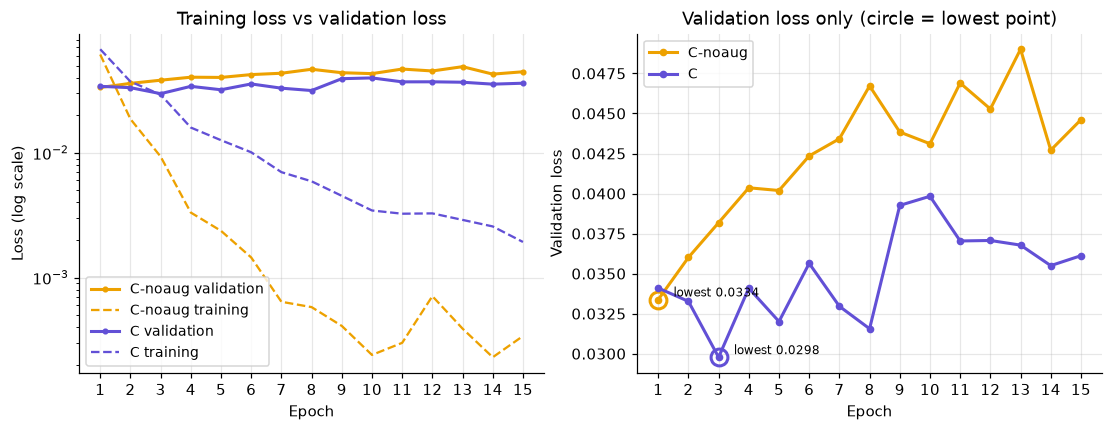

,lowest val loss,at epoch,final val loss,rise after lowest (%),final train loss,epochs with val loss above epoch-1 value
config,,,,,,
C-noaug,0.03338,1,0.04461,33.64290,0.00034,14
C,0.02978,3,0.03612,21.28946,0.00193,8


In [29]:
# Output file: outputs/fig_aug_val_loss.png
# C-noaug vs C: same model, LR and seed; only augmentation differs.
# Left: training vs validation loss. Right: validation loss alone (the fair overfitting measure),
# with its lowest point marked: a curve that climbs after its lowest point is overfitting.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rows = []
for c in ["C-noaug", "C"]:
    df, col = results[c], CONFIGS[c]["color"]
    axes[0].plot(df.epoch, df.eval_loss, "-o", ms=3, lw=2, color=col, label=f"{c} validation")
    axes[0].plot(df.epoch, df.train_loss, "--", lw=1.5, color=col, label=f"{c} training")
    axes[1].plot(df.epoch, df.eval_loss, "-o", ms=4, lw=2, color=col, label=c)
    low = df.loc[df.eval_loss.idxmin()]
    axes[1].plot(low.epoch, low.eval_loss, "o", ms=11, mfc="none", mec=col, mew=2)
    axes[1].annotate(f"lowest {low.eval_loss:.4f}", (low.epoch, low.eval_loss), xytext=(10, 2),
                     textcoords="offset points", fontsize=8)
    rows.append({"config": c,
                 "lowest val loss": low.eval_loss,
                 "at epoch": int(low.epoch),
                 "final val loss": df.eval_loss.iloc[-1],
                 "rise after lowest (%)": 100 * (df.eval_loss.iloc[-1] / low.eval_loss - 1),
                 "final train loss": df.train_loss.iloc[-1],
                 "epochs with val loss above epoch-1 value": int((df.eval_loss > df.eval_loss.iloc[0]).sum())})
axes[0].set_yscale("log")
axes[0].set_ylabel("Loss (log scale)")
axes[0].set_title("Training loss vs validation loss")
axes[1].set_ylabel("Validation loss")
axes[1].set_title("Validation loss only (circle = lowest point)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(results["C"].epoch)
    ax.legend(fontsize=9)
save(fig, "fig_aug_val_loss.png")
plt.show()

aug_loss = pd.DataFrame(rows).set_index("config")
aug_loss.round(5)

### What the curves show

- **A (scratch CNN)** is still improving at epoch 15 (both curves still falling), so it was limited by the
  15-epoch budget; it also has a bumpy middle (epochs 7–8) where validation got worse before recovering.
  Its training curve sits close to, sometimes above, the validation curve because it trains on augmented
  images with dropout on.
- **The ResNet configs (B′, C-noaug, C)** are already near their final level after epoch 1: the pretrained
  features do most of the work from the start. After that, their validation curves are almost flat.
- **The learning-rate drops** (dotted lines) visibly help A settle; for the ResNet configs there is little
  left to gain.

**Augmentation (second figure and table):**
- Without augmentation, the training loss falls towards zero (the model memorises the 20,000 fixed training
  images) while the **validation loss is lowest at epoch 1 and then climbs** for the rest of training:
  the classic sign of overfitting.
- With augmentation, training loss falls more slowly (each epoch shows slightly different images), the
  validation loss reaches its lowest point later, climbs less, and stays **below C-noaug's after the first
  epoch**.
- Accuracy hardly differs (section 3), because the extra validation loss of C-noaug likely comes from being *more
  confidently wrong / less confidently right*, not from many more mistakes. Augmentation made the model's
  probabilities on unseen images better, which is why C is kept as the final model.

## 5. Learning-rate sweep (Part c)

Before the full runs, Config C's setup was trained for 3 epochs at three learning rates (1e-3, 1e-4, 1e-5)
on the **subset** (2,000 train / 500 val images), all on the same machine. Purpose: evidence for the
learning rate used by C and C-noaug, instead of "1e-4 is standard".

With only 500 val images, one image is 0.2 percentage points, so accuracy alone is too coarse to separate
the three; the 95% intervals in the table show this. The **validation loss over the epochs** shows the behaviour
of each learning rate much more clearly.

Decision rule used in `02` (stated there before the sweep ran): keep 1e-4 unless another learning rate
beats it by at least 1 percentage point of val accuracy.

**Output files** (in `outputs/`): `fig_lr_sweep.png`

In [30]:
# Output file: none (display only)
N_SWEEP_VAL = SUBSET_SIZE["val"]   # the sweep always ran on the subset
DEFAULT_LR, MARGIN = 1e-4, 0.01    # decision rule from 02: keep 1e-4 unless another LR wins by >= 1 pp

sweep_rows = []
for c, lr in SWEEP.items():
    df = sweep[c]
    best_acc = df.eval_acc.max()
    lo, hi = wilson_ci(best_acc, N_SWEEP_VAL)
    sweep_rows.append({
        "lr": lr,
        "val acc per epoch": ", ".join(f"{a:.3f}" for a in df.eval_acc),
        "best val acc": best_acc,
        "95% interval": f"{lo:.3f} – {hi:.3f}",
        "val loss per epoch": ", ".join(f"{l:.3f}" for l in df.eval_loss),
        "val loss falls every epoch": bool((df.eval_loss.diff().dropna() < 0).all()),
        "final val loss": df.eval_loss.iloc[-1],
        "final train loss": df.train_loss.iloc[-1],
    })
sweep_table = pd.DataFrame(sweep_rows).set_index("lr")

# Apply 02's decision rule to the sweep, and check it matches the LR the full C run actually used.
default_acc = sweep_table.loc[DEFAULT_LR, "best val acc"]
challengers = sweep_table[(sweep_table.index != DEFAULT_LR) &
                          (sweep_table["best val acc"] >= default_acc + MARGIN)]
rule_lr = challengers["best val acc"].idxmax() if len(challengers) else DEFAULT_LR
used_lr = results["C"].lr.iloc[0]
print(f"subset: {N_SWEEP_VAL} val images, 1 image = {100 / N_SWEEP_VAL:.1f} pp")
print(f"decision rule picks lr = {rule_lr:g}; full C and C-noaug runs used lr = {used_lr:g} "
      f"and {results['C-noaug'].lr.iloc[0]:g}")
assert rule_lr == used_lr == results["C-noaug"].lr.iloc[0]
sweep_table.round(4)

subset: 500 val images, 1 image = 0.2 pp
decision rule picks lr = 0.0001; full C and C-noaug runs used lr = 0.0001 and 0.0001


,val acc per epoch,best val acc,95% interval,val loss per epoch,val loss falls every epoch,final val loss,final train loss
lr,,,,,,,
0.00100,"0.968, 0.962, 0.968",0.968,0.949 – 0.980,"0.071, 0.129, 0.095",False,0.0955,0.0475
0.00010,"0.968, 0.976, 0.970",0.976,0.959 – 0.986,"0.070, 0.061, 0.054",True,0.0543,0.0272
0.00001,"0.948, 0.968, 0.972",0.972,0.954 – 0.983,"0.216, 0.115, 0.087",True,0.0872,0.1130


saved outputs/fig_lr_sweep.png


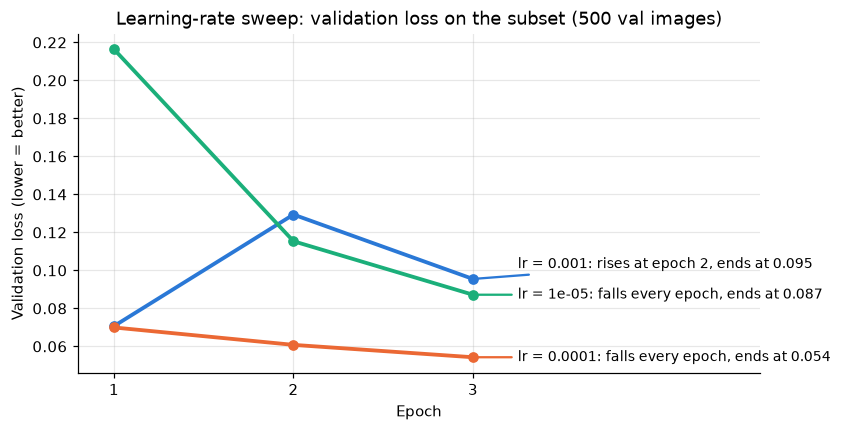

In [31]:
# Output file: outputs/fig_lr_sweep.png
# One chart: validation loss per epoch for each learning rate (lower = better), each line labelled directly.
# Accuracy is left to the table above: on 500 images it cannot separate the three.
fig, ax = plt.subplots(figsize=(8, 4))
labels = []
for c, lr in SWEEP.items():
    df, col = sweep[c], SWEEP_COLORS[c]
    ax.plot(df.epoch, df.eval_loss, "-o", ms=6, lw=2.5, color=col)
    rises = df.epoch[df.eval_loss.diff() > 0].tolist()   # epochs where the loss went UP
    behaviour = f"rises at epoch {', '.join(map(str, rises))}" if rises else "falls every epoch"
    labels.append((df.eval_loss.iloc[-1], df.epoch.iloc[-1], col,
                   f"lr = {lr:g}: {behaviour}, ends at {df.eval_loss.iloc[-1]:.3f}"))

# Spread the labels vertically so lines that end close together do not get overlapping text.
y_min, y_max = ax.get_ylim()
gap = 0.09 * (y_max - y_min)
labels.sort()
label_y = []
for y, *_ in labels:
    label_y.append(max(y, label_y[-1] + gap) if label_y else y)
for (y, x, col, text), ly in zip(labels, label_y):
    ax.annotate(text, xy=(x, y), xytext=(x + 0.25, ly), va="center", fontsize=9,
                arrowprops=dict(arrowstyle="-", color=col, lw=1.5))

last_epoch = sweep[next(iter(SWEEP))].epoch.max()
ax.set_xticks(range(1, last_epoch + 1))
ax.set_xlim(0.8, last_epoch + 1.6)   # room for the labels
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss (lower = better)")
ax.set_title(f"Learning-rate sweep: validation loss on the subset ({N_SWEEP_VAL} val images)")
save(fig, "fig_lr_sweep.png")
plt.show()

### What the sweep shows

- **lr = 1e-3 is too large for pretrained weights:** its validation loss *jumps up* after the first epoch.
  Steps this big disturb the ImageNet features that make the model good.
- **lr = 1e-5 is too small:** it starts far behind (highest validation loss after epoch 1) and is still
  catching up after 3 epochs, so it would need more than the 15-epoch budget all configs share.
- **lr = 1e-4 learns fast and stays stable:** its validation loss falls every epoch and is the lowest at the
  end, and it has the best accuracy.
- **Accuracy alone cannot rank them:** on 500 images the 95% intervals of all three overlap. The decision
  therefore rests on the loss behaviour, and the pre-stated rule (keep 1e-4 unless another LR wins by
  ≥ 1 pp) kept 1e-4, which is what the full C and C-noaug runs used (checked in the cell above).

*Limitation (state in the report):* 3 epochs on a subset is a guide, not proof for the full 15-epoch run.
The full-run curves (section 4) are consistent with it: at 1e-4, C and C-noaug reach their final level
within the first few epochs without the loss blowing up.

## 6. Error analysis of Config C (Part e)

The test set has **no labels**, so we cannot tell which test predictions are right or wrong. Correct and
incorrect samples therefore come from the **validation set**: 5,000 labelled images the model never trained
on, predicted by the saved best epoch of C (`preds_C_seed42.csv`). A few test images with their predicted
labels are shown at the end for completeness.

`prob_dog` is the model's probability that the image is a dog; it predicts dog when this is above 0.5.
**Confidence** = the probability of the class it predicted (0.5 = unsure, 1.0 = certain).

What this section answers:
- Does C make more mistakes on cats or on dogs? (confusion matrix)
- Can its confidence be trusted? (how often it is right at each confidence level)
- What do its correct and wrong predictions look like, and what are its strengths and weaknesses?

**Output files** (in `outputs/`): `fig_confusion.png`, `fig_samples_correct.png`, `fig_samples_wrong.png`, `fig_all_misclassified_C.png`, `fig_test_samples.png`

Config C: 4955 of 5000 val images correct (99.10%), 45 misclassified

              precision    recall  f1-score   support

         cat     0.9904    0.9916    0.9910      2500
         dog     0.9916    0.9904    0.9910      2500

    accuracy                         0.9910      5000
   macro avg     0.9910    0.9910    0.9910      5000
weighted avg     0.9910    0.9910    0.9910      5000

saved outputs/fig_confusion.png


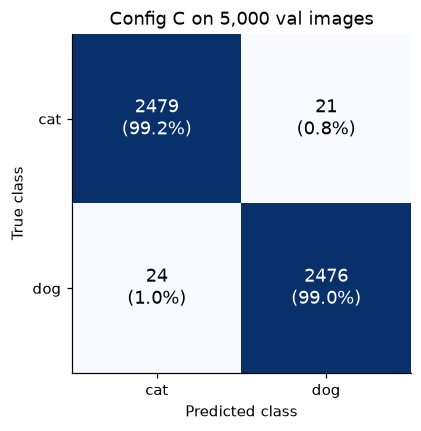

In [32]:
# Output file: outputs/fig_confusion.png
# One row per val image: true class, predicted class, confidence, correct or not.
pc = preds["C"].copy()
pc["true_class"] = pc.label.map(IDX_TO_CLASS)
pc["pred_class"] = pc.pred.map(IDX_TO_CLASS)
pc["correct"] = pc.label == pc.pred
pc["confidence"] = np.where(pc.pred == 1, pc.prob_dog, 1 - pc.prob_dog)
assert abs(pc.correct.mean() - table.loc["C", "best_val_acc"]) < 1e-9, "preds file does not match results file"

print(f"Config C: {pc.correct.sum()} of {len(pc)} val images correct ({pc.correct.mean():.2%}), "
      f"{(~pc.correct).sum()} misclassified\n")
print(classification_report(pc.label, pc.pred, target_names=[IDX_TO_CLASS[0], IDX_TO_CLASS[1]], digits=4))

# Confusion matrix: rows = true class, columns = predicted class; each cell shows count and % of that row.
cm = confusion_matrix(pc.label, pc.pred)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center", fontsize=12,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
names = [IDX_TO_CLASS[0], IDX_TO_CLASS[1]]
ax.set_xticks([0, 1], names)
ax.set_yticks([0, 1], names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"Config C on {len(pc):,} val images")
ax.grid(False)
save(fig, "fig_confusion.png")
plt.show()

In [33]:
# Output file: none (display only)
# Can C's confidence be trusted? Group the val images by confidence and count how often C is right in each group.
bins = [0.5, 0.9, 0.99, 0.999, 1.0]
pc["confidence_group"] = pd.cut(pc.confidence, bins=bins, include_lowest=True,
                                labels=["0.50–0.90", "0.90–0.99", "0.99–0.999", "above 0.999"])
by_conf = pc.groupby("confidence_group", observed=False).agg(
    images=("correct", "size"), misclassified=("correct", lambda s: int((~s).sum())),
    accuracy=("correct", "mean"))
by_conf["share of all misclassified"] = by_conf.misclassified / by_conf.misclassified.sum()
by_conf.round(4)

,images,misclassified,accuracy,share of all misclassified
confidence_group,,,,
0.50–0.90,64,25,0.6094,0.5556
0.90–0.99,115,8,0.9304,0.1778
0.99–0.999,201,5,0.9751,0.1111
above 0.999,4620,7,0.9985,0.1556


saved outputs/fig_samples_correct.png


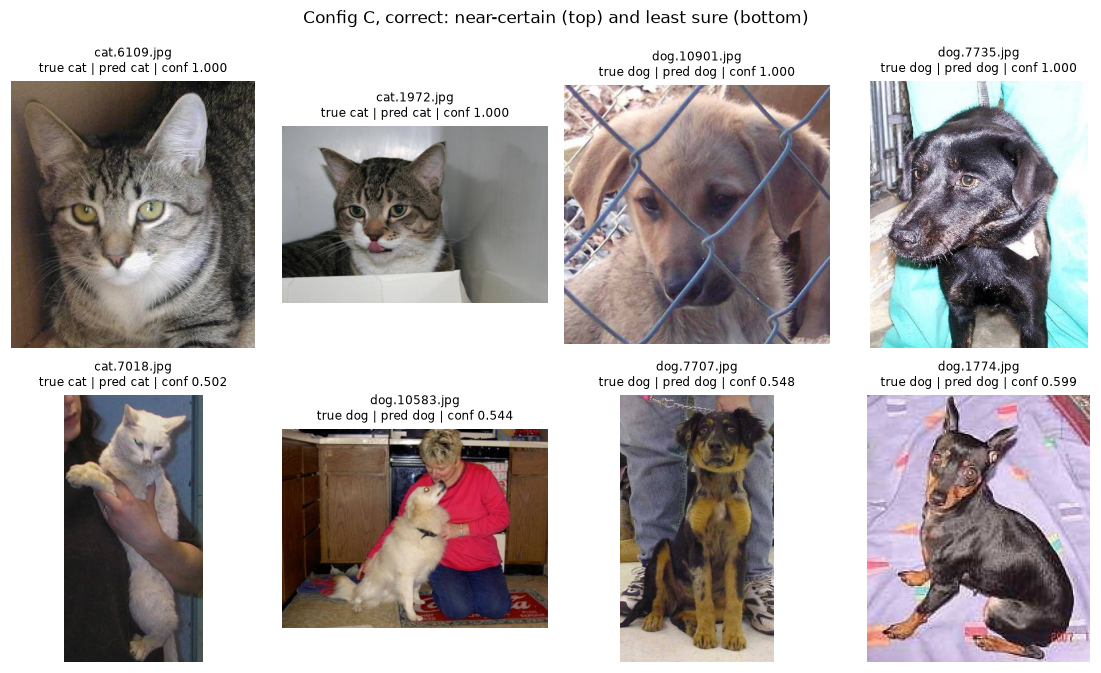

saved outputs/fig_samples_wrong.png


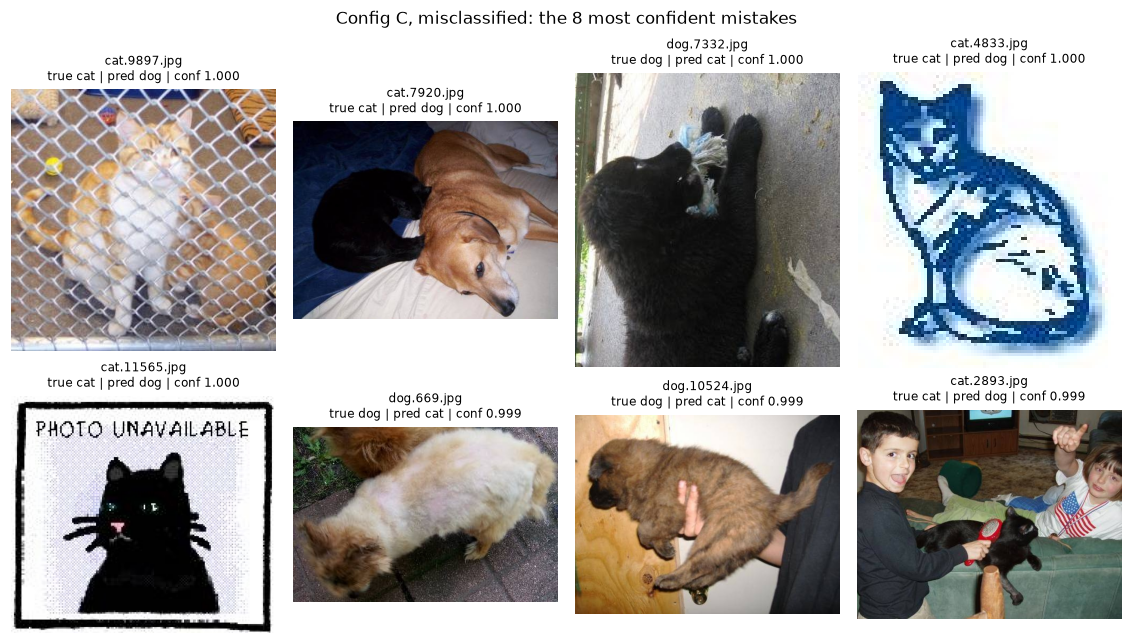

In [34]:
# Output files: outputs/fig_samples_correct.png, outputs/fig_samples_wrong.png
def show_grid(df, title, name, caption, ncols=4, size=2.6, dpi=None):
    """One thumbnail per row of df (needs a 'path' column relative to DATA_DIR), captioned by caption(row)."""
    nrows = int(np.ceil(len(df) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * (size + 0.5)), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, df.iterrows()):
        ax.imshow(Image.open(DATA_DIR / r.path).convert("RGB"))
        ax.set_title(caption(r), fontsize=8)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / name, **({"dpi": dpi} if dpi else {}))
    print("saved", (OUTPUT_DIR / name).relative_to(OUTPUT_DIR.parent).as_posix())
    plt.show()


def val_caption(r):
    return f"{r.path.split('/')[-1]}\ntrue {r.true_class} | pred {r.pred_class} | conf {r.confidence:.3f}"


# Correct: top row = 2 cats + 2 dogs C was (near) certain about, picked at random among those so they are not
# just the first files alphabetically; bottom row = the 4 correct images C was LEAST sure about.
certain = pd.concat([pc[pc.correct & (pc.label == k) & (pc.confidence > 0.999)].sample(2, random_state=SEED)
                     for k in (0, 1)])
least_sure = pc[pc.correct].nsmallest(4, "confidence")
show_grid(pd.concat([certain, least_sure]),
          "Config C, correct: near-certain (top) and least sure (bottom)", "fig_samples_correct.png", val_caption)

# Wrong: the 8 mistakes C was most confident about (the most informative failures).
wrong = pc[~pc.correct].sort_values("confidence", ascending=False)
show_grid(wrong.head(8), "Config C, misclassified: the 8 most confident mistakes", "fig_samples_wrong.png",
          val_caption)

saved outputs/fig_all_misclassified_C.png


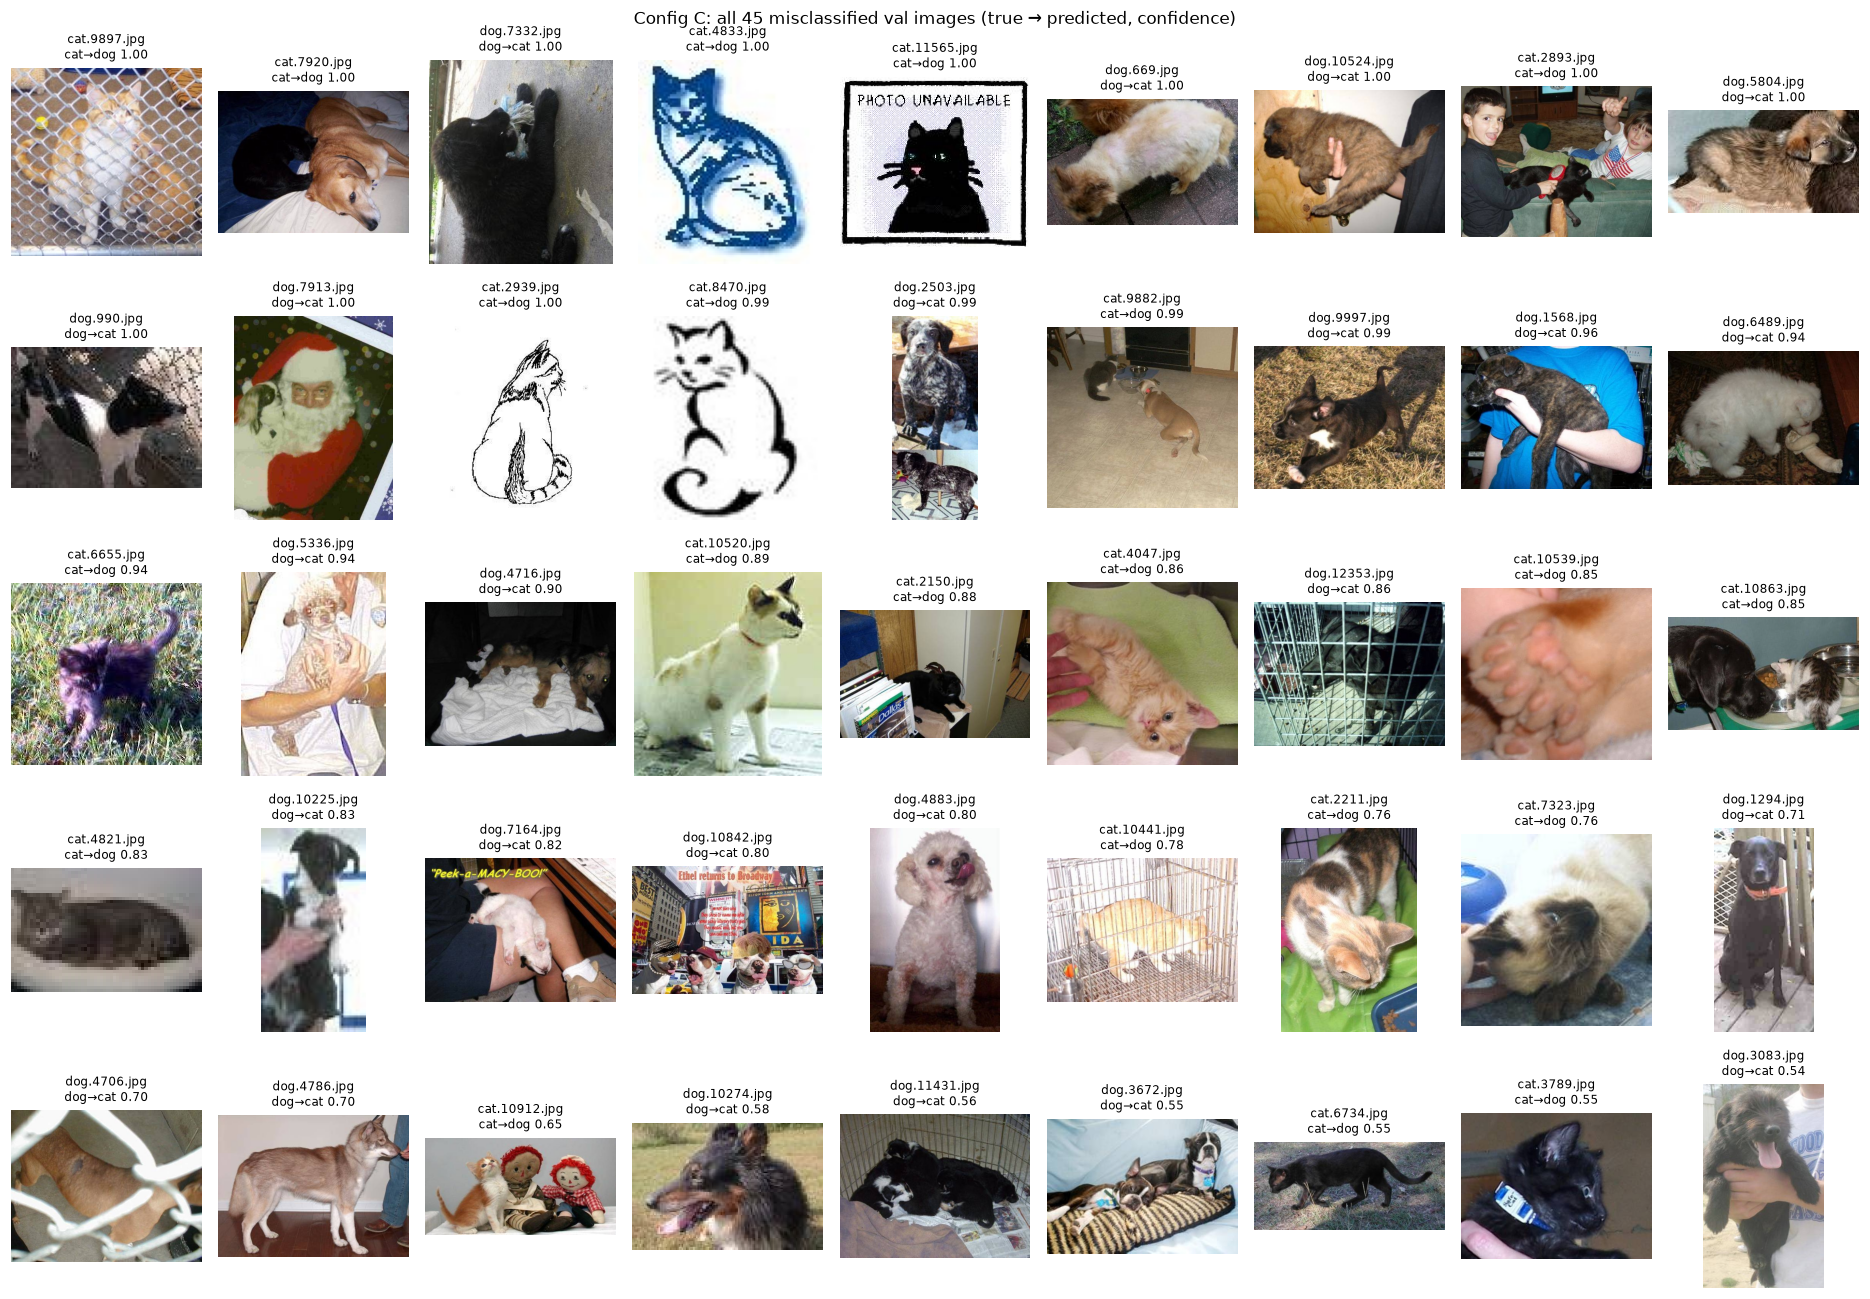

In [35]:
# Output file: outputs/fig_all_misclassified_C.png
# All misclassified val images on one sheet, most confident first: used to choose the cases to discuss.
# Saved at lower resolution to keep the file small (it is for browsing, not for the report).
show_grid(wrong, f"Config C: all {len(wrong)} misclassified val images (true → predicted, confidence)",
          "fig_all_misclassified_C.png", ncols=9, size=1.9, dpi=80,
          caption=lambda r: f"{r.path.split('/')[-1]}\n{r.true_class}→{r.pred_class} {r.confidence:.2f}")

submission predictions: {'dog': 256, 'cat': 244} (500 test images)
saved outputs/fig_test_samples.png


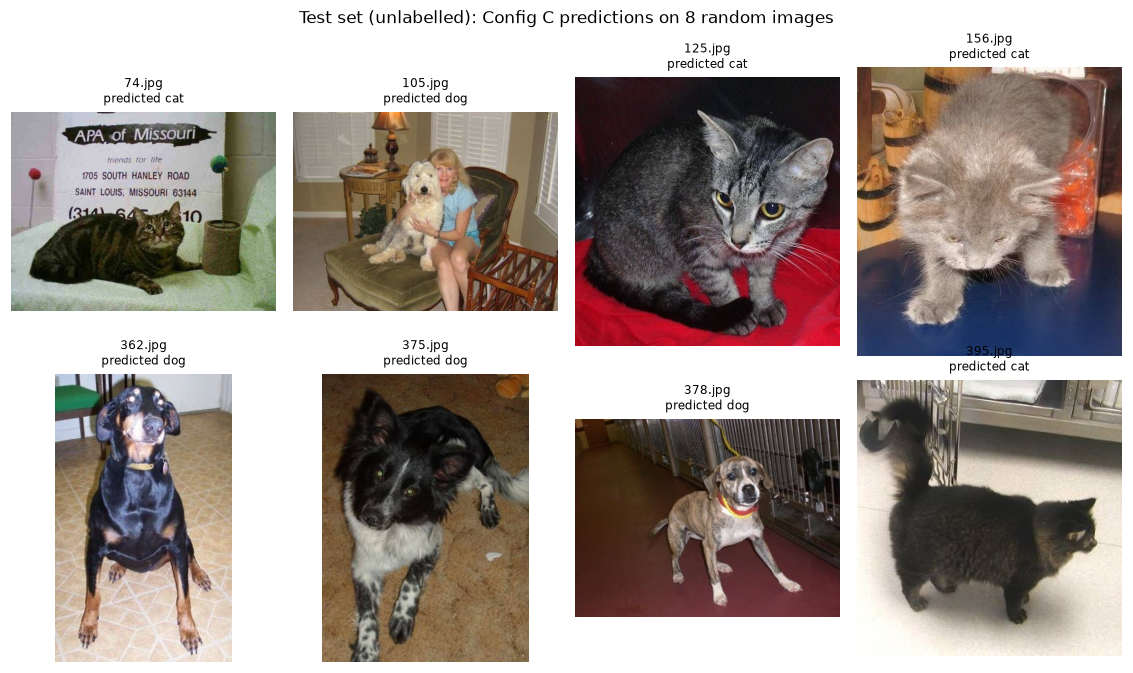

In [36]:
# Output file: outputs/fig_test_samples.png
# Test set (no labels): C's predicted labels from submission.csv on 8 random test images.
submission = pd.read_csv(OUTPUT_DIR.parent / "submission.csv")
print("submission predictions:", submission.label.map(IDX_TO_CLASS).value_counts().to_dict(),
      f"({len(submission)} test images)")

test_sample = submission.sample(8, random_state=SEED).sort_values("id")
test_sample = test_sample.assign(path=[f"test/{i}.jpg" for i in test_sample.id])
show_grid(test_sample, "Test set (unlabelled): Config C predictions on 8 random images", "fig_test_samples.png",
          caption=lambda r: f"{r.id}.jpg\npredicted {IDX_TO_CLASS[r.label]}")

### Strengths and weaknesses (Part e asks for 1–2 cases)

**Balanced across classes:** the confusion matrix shows cats and dogs are misclassified about equally often,
so the model has no bias towards one class.

**Strength: its confidence is informative.** When C is near-certain (confidence above 0.999, the vast
majority of images) it is almost always right, and a large share of its mistakes sit in the small group of
images where it is unsure (see the confidence table). A low confidence is therefore a useful warning that a
prediction should be checked. The near-certain correct examples cover different breeds, colours, poses and
backgrounds, including an animal behind a fence.

**Weakness: some mistakes are made with full confidence.** The most confident mistakes
(`fig_samples_wrong.png`, browse all of them in `fig_all_misclassified_C.png`) fall into recognisable types,
each with a CNN reason:

| Example (this run) | What is in the image | Why a CNN gets it wrong |
|---|---|---|
| `cat.7920.jpg` | A black cat lying against a large dog | Two animals, one label: the dog's features dominate the picture |
| `cat.2893.jpg` | Two children with a small cat between them | The animal is small; people and clutter dominate the features |
| `cat.9897.jpg` | A cat behind a chain-link fence | Occlusion: the fence pattern covers the animal's texture and shape |
| `cat.4833.jpg` | A blue line drawing of a cat | Not a photo: nothing like the images the model learned from |
| `cat.11565.jpg` | A "PHOTO UNAVAILABLE" placeholder with a cartoon cat | Not a real photo: noise in the dataset itself |
| `dog.7332.jpg`, `dog.10524.jpg` | Fluffy black/brown puppies in unusual poses | Puppy fur and round faces look cat-like; pose hides the usual cues |

**Suggested pair for the report:** `cat.7920.jpg` (a genuine ambiguity: one label for an image containing two
animals; arguably not a model error at all) and `cat.4833.jpg` or `cat.11565.jpg` (images unlike the photos
the model was trained on, showing it relies on photographic texture and shape).

*If the model is retrained, the file names above change; re-check them against `fig_samples_wrong.png`.*

## 7. Config A vs Config C, image by image (Parts e, f)

A and C are the only configs with saved per-image predictions on the same 5,000 val images, so for them we
can go beyond "how many are wrong" and ask **which** images each gets wrong:

- **C right, A wrong:** what the pretrained ResNet fixes
- **A right, C wrong:** what it breaks
- **Both wrong:** images that are hard for any model (or wrongly labelled)

**McNemar's test** uses only the images where the two models disagree: if C were no better than A, those
disagreements would split roughly 50/50 between "only C right" and "only A right". The p-value is the chance
of a split at least as lopsided as the one observed if they were equally good.

**Output files** (in `outputs/`): `fig_A_vs_C.png`

In [37]:
# Output file: none (display only)
# Put A's and C's prediction for each val image side by side (matched on the image path).
pa = preds["A"]
both = pa.rename(columns={"pred": "A_pred", "prob_dog": "A_prob_dog"}).merge(
    preds["C"][["path", "pred", "prob_dog"]].rename(columns={"pred": "C_pred", "prob_dog": "C_prob_dog"}),
    on="path", validate="one_to_one")
both["true_class"] = both.label.map(IDX_TO_CLASS)
a_ok, c_ok = both.A_pred == both.label, both.C_pred == both.label

# 2x2 table: how many images each combination of right/wrong.
contingency = pd.DataFrame([[(a_ok & c_ok).sum(), (a_ok & ~c_ok).sum()],
                            [(~a_ok & c_ok).sum(), (~a_ok & ~c_ok).sum()]],
                           index=["A right", "A wrong"], columns=["C right", "C wrong"])

# McNemar exact test: under "equally good", the disagreements split 50/50 (a binomial test with p = 0.5).
only_c, only_a = int((~a_ok & c_ok).sum()), int((a_ok & ~c_ok).sum())
p_value = binomtest(only_a, only_a + only_c, 0.5).pvalue

print(f"Images where they disagree: {only_c + only_a}")
print(f"  C right, A wrong (fixed by C):  {only_c}")
print(f"  A right, C wrong (broken by C): {only_a}")
print(f"  Both wrong (hard for both):     {int((~a_ok & ~c_ok).sum())}")
print(f"McNemar exact test p-value = {p_value:.1e}  ->  "
      f"{'C is significantly better than A' if p_value < 0.05 else 'no significant difference'}")
print(f"Of A's {int((~a_ok).sum())} mistakes, C fixes {only_c / (~a_ok).sum():.0%}; "
      f"of C's {int((~c_ok).sum())} mistakes, {int((~a_ok & ~c_ok).sum())} are also mistakes for A\n")

# Which class do they get wrong? (misclassified count per true class)
per_class = pd.DataFrame({
    "A misclassified": (~a_ok).groupby(both.true_class).sum(),
    "C misclassified": (~c_ok).groupby(both.true_class).sum(),
    "images": both.groupby("true_class").size(),
})
print(per_class.to_string(), "\n")
contingency

Images where they disagree: 441
  C right, A wrong (fixed by C):  420
  A right, C wrong (broken by C): 21
  Both wrong (hard for both):     24
McNemar exact test p-value = 1.5e-97  ->  C is significantly better than A
Of A's 444 mistakes, C fixes 95%; of C's 45 mistakes, 24 are also mistakes for A

            A misclassified  C misclassified  images
true_class                                          
cat                     207               21    2500
dog                     237               24    2500 



,C right,C wrong
A right,4535,21
A wrong,420,24


saved outputs/fig_A_vs_C.png


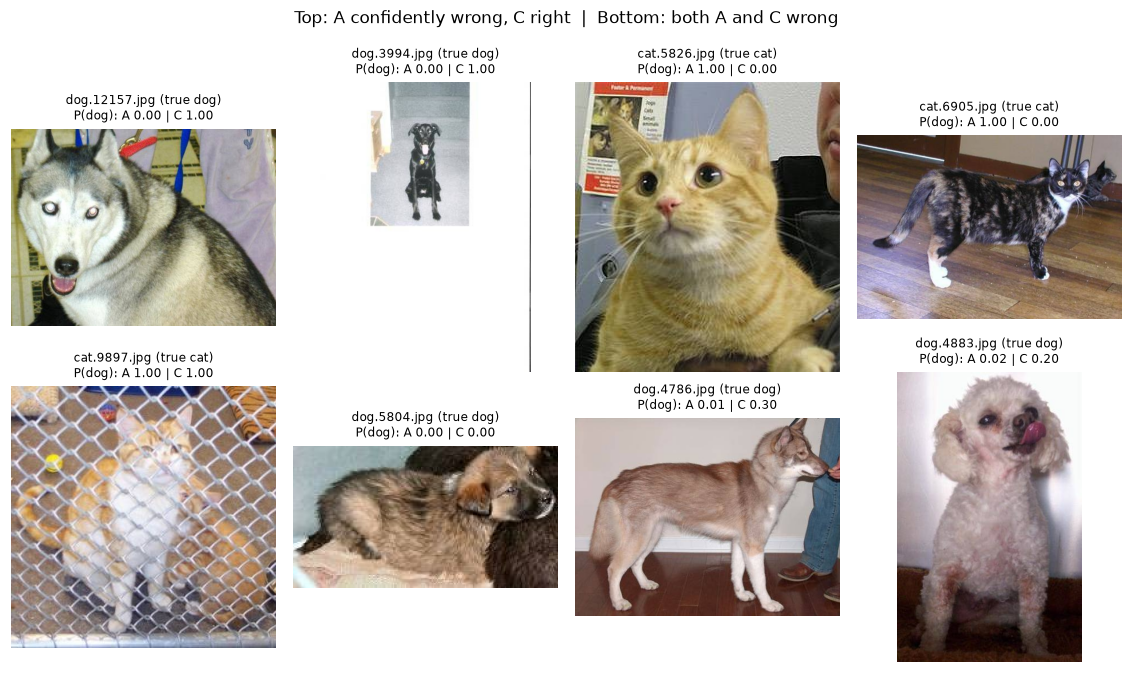

In [38]:
# Output file: outputs/fig_A_vs_C.png
# Top row: images A got confidently wrong but C got right. Bottom row: images both got wrong.
def ac_caption(r):
    return (f"{r.path.split('/')[-1]} (true {r.true_class})\n"
            f"P(dog): A {r.A_prob_dog:.2f} | C {r.C_prob_dog:.2f}")


both["A_wrongness"] = (both.A_prob_dog - both.label).abs()   # 1.0 = A was certain of the wrong class
fixed = both[~a_ok & c_ok].nlargest(4, "A_wrongness")
hard = both[~a_ok & ~c_ok].nlargest(4, "A_wrongness")
show_grid(pd.concat([fixed, hard]),
          "Top: A confidently wrong, C right  |  Bottom: both A and C wrong", "fig_A_vs_C.png", ac_caption)

### What the image-by-image comparison shows

- **C does not just make fewer mistakes, it fixes almost all of A's.** Nearly every image A gets wrong, C gets
  right, while C introduces only a handful of new mistakes. McNemar's test confirms the difference is far too
  lopsided to be chance (the p-value is essentially zero). This is the paired test that backs up the A vs C
  "real improvement" in section 3.
- **What C fixes are ordinary photos** (top row of `fig_A_vs_C.png`): clear, well-lit cats and dogs that A was
  nonetheless certain about the wrong way. Trained from scratch on 20,000 images for 15 epochs, A has not
  learned robust cat/dog features; C starts from features learned on over a million ImageNet images.
- **What both get wrong are genuinely hard images** (bottom row): an animal behind a fence, a puppy curled up,
  a dog in side view with wolf-like markings, a curly-coated dog with a cat-like face. About half of C's
  mistakes are also A's mistakes, so C's remaining errors are concentrated on images that are hard for any
  model, not on random photos.
- **Neither model favours one class:** both misclassify cats and dogs about equally often (table above).

*Limitation:* A and C differ in both architecture and pretraining, so this shows their combined effect.

## 8. Summary for the report

The key numbers in one place, grouped by report part, all taken from the variables computed above (so they update automatically if anything is re-run), plus which saved file goes with which part.

**Output files** (in `outputs/`): none (prints the summary)

In [39]:
# Output file: none (display only)
# Key numbers for the report, all taken from the variables computed above (nothing retyped).
c = table.loc["C"]

print("PART c — learning rate")
print(f"  C and C-noaug use lr = {used_lr:g} (chosen by the sweep's decision rule)")
for lr, r in sweep_table.iterrows():
    print(f"  sweep lr = {lr:g}: final val loss {r['final val loss']:.3f}, best val acc {r['best val acc']:.1%}"
          + ("" if r["val loss falls every epoch"] else "  (val loss rises)"))

print("\nPART d — validation accuracy")
print(f"  Final model C: {c.best_val_acc:.2%} (95% interval {c.ci95_low:.2%}–{c.ci95_high:.2%}), "
      f"{int(c.val_misclassified)} of {N_VAL:,} misclassified, best epoch {int(c.best_epoch)} of {int(c.epochs_run)}")
for cfg, r in table.iterrows():
    print(f"  {CONFIGS[cfg]['label']:<34} {r.best_val_acc:.2%}  ({int(r.val_misclassified)} misclassified)")

print("\nPART e — correct and incorrect samples (val set; test set is unlabelled)")
print(f"  C misclassified: {int(per_class.loc['cat', 'C misclassified'])} cats as dog, "
      f"{int(per_class.loc['dog', 'C misclassified'])} dogs as cat")
top = by_conf.iloc[-1]
print(f"  When near-certain (confidence above 0.999, {int(top.images)} images): {top.accuracy:.2%} accurate")
low = by_conf.iloc[0]
print(f"  When unsure (confidence 0.50–0.90, {int(low.images)} images): {low.accuracy:.1%} accurate, "
      f"holding {low['share of all misclassified']:.0%} of all mistakes")

print("\nPART f — comparison")
for _, r in chain.iterrows():
    print(f"  {r.step:<13} {r['what changes']:<40} {r.diff_pp:+.2f} pp ({r.diff_images:+d} images), "
          f"interval {r.diff_ci95_pp} pp -> {r.verdict}")
print(f"  Augmentation: lowest val loss C-noaug {aug_loss.loc['C-noaug', 'lowest val loss']:.4f} "
      f"(epoch {aug_loss.loc['C-noaug', 'at epoch']}) vs C {aug_loss.loc['C', 'lowest val loss']:.4f} "
      f"(epoch {aug_loss.loc['C', 'at epoch']}); final {aug_loss.loc['C-noaug', 'final val loss']:.4f} vs "
      f"{aug_loss.loc['C', 'final val loss']:.4f}")
print(f"  A vs C image by image: C fixes {only_c} of A's mistakes, breaks {only_a}; McNemar p = {p_value:.1e}")

# Which saved file goes with which report part (and check each one exists).
report_files = {
    "comparison_table.csv": "Part d, f", "fig_misclassified.png": "Part d, f", "comparison_chain.csv": "Part f",
    "fig_curves.png": "Part b, f", "fig_aug_val_loss.png": "Part f", "fig_lr_sweep.png": "Part c",
    "fig_confusion.png": "Part e", "fig_samples_correct.png": "Part e", "fig_samples_wrong.png": "Part e",
    "fig_test_samples.png": "Part e", "fig_A_vs_C.png": "Part e, f",
    "fig_all_misclassified_C.png": "working aid (choose cases for Part e)",
}
print("\nFILES in outputs/")
for name, part in report_files.items():
    status = "ok" if (OUTPUT_DIR / name).exists() else "MISSING"
    print(f"  [{status}] {name:<30} {part}")

PART c — learning rate
  C and C-noaug use lr = 0.0001 (chosen by the sweep's decision rule)
  sweep lr = 0.001: final val loss 0.095, best val acc 96.8%  (val loss rises)
  sweep lr = 0.0001: final val loss 0.054, best val acc 97.6%
  sweep lr = 1e-05: final val loss 0.087, best val acc 97.2%

PART d — validation accuracy
  Final model C: 99.10% (95% interval 98.80%–99.33%), 45 of 5,000 misclassified, best epoch 11 of 15
  A: custom CNN (scratch)            91.12%  (444 misclassified)
  B: frozen ResNet-18 + SVM          98.98%  (51 misclassified)
  B′: frozen ResNet-18 + linear      98.84%  (58 misclassified)
  C-noaug: fine-tuned without aug    99.06%  (47 misclassified)
  C: fine-tuned + aug (final)        99.10%  (45 misclassified)

PART e — correct and incorrect samples (val set; test set is unlabelled)
  C misclassified: 21 cats as dog, 24 dogs as cat
  When near-certain (confidence above 0.999, 4620 images): 99.85% accurate
  When unsure (confidence 0.50–0.90, 64 images): 60.9%